# 04.2 Regresión lineal y logística: búsqueda de hiperparámetros (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en `README.md`)

Instrucciones:

- La búsqueda usa Optuna con `N_TRIALS` pruebas y la misma validación en todos los modelos: 5 grupos separados por animal y la semilla `SEED`.
- Nombre de los archivos que se generan: `linear_clf` y `linear_reg`. Es el primer argumento de `tune(...)`, y el notebook de modelado lo usa en `load_best(...)`.
- Se hace con `tune(...)` de `tuning.py`. Solo hay que definir `make_pipe` (el pipeline) y `space` (qué ajustes se prueban y en qué rango).
- En modelos lentos se puede usar `subsample=0.2` (el 20 % de los animales).
- Si cambian las variables o los datos, hay que repetir la búsqueda. El notebook de modelado lo comprueba.
- No usar `test`.

In [ ]:
# 04.2 Regresión lineal y logística: búsqueda de hiperparámetros (experimento 2)

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]

## Inputs

 Se agregan raza, color y ciudad (CAT_HIGH estaba desde el exp1 en este modelo, pero en regresión reemplazamos age_days por age_log).

In [ ]:
# --- Inputs ---
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC
FEATURES_EXP2_REG = CAT_LOW + CAT_HIGH + BINARY + [c for c in NUMERIC if c != "age_days"] + NUMERIC_LOG

print("El experimento 2 usa estas variables:")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)
# Clasificación: todas las filas
y_clf = data["y_outcome"]
# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'prior_stays', 'hour', 'month', 't_months', 'age_log']


# Qué se ajusta
 (Celda Markdown idéntica al Experimento 1 para Linear/Logistic)

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1.

Búsqueda de Logistic Regression (clasificación): 20 pruebas con 63,681 filas y 57,564 animales.
Prueba 1/20: resultado 0.478 | mejor hasta ahora 0.478
Prueba 2/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 3/20: resultado 0.417 | mejor hasta ahora 0.481
Prueba 4/20: resultado 0.464 | mejor hasta ahora 0.481
Prueba 5/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 6/20: resultado 0.442 | mejor hasta ahora 0.481
Prueba 7/20: resultado 0.461 | mejor hasta ahora 0.481
Prueba 8/20: resultado 0.435 | mejor hasta ahora 0.481
Prueba 9/20: resultado 0.480 | mejor hasta ahora 0.481
Prueba 10/20: resultado 0.480 | mejor hasta ahora 0.481
Prueba 11/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 12/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 13/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 14/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 15/20: resultado 0.464 | mejor hasta ahora 0.481
Prueba 16/20: resultado 0.481 | mejor hasta ahora 0.481
Prueba 17/20: res

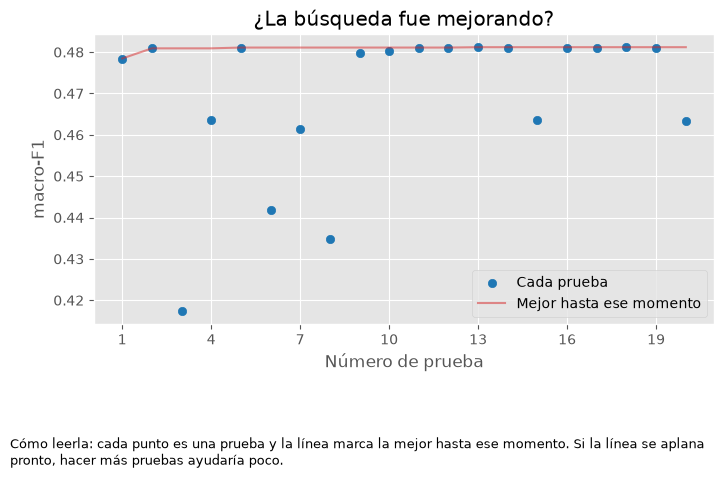

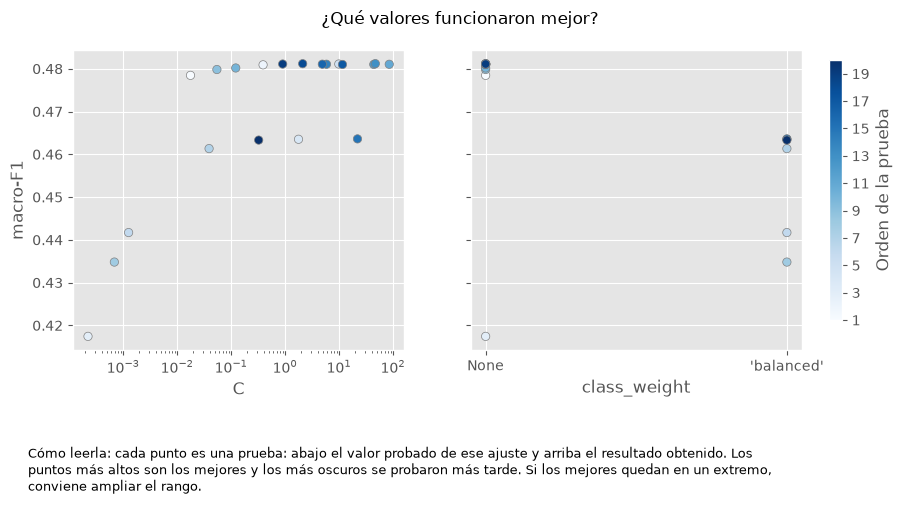

In [ ]:
# --- 1. Clasificación (Regresión Logística) ---
# Objetivo: y_outcome (5 clases), macro-F1.

def make_pipe_clf(params):
    # max_iter alto para asegurar que el modelo converja
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF)),
                     ("model", LogisticRegression(max_iter=2000, **params))])

def space_clf(trial):
    return {"C": trial.suggest_float("C", 1e-4, 1e2, log=True),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

study_clf = tune(
    "linear_clf", make_pipe_clf, space_clf, data[FEATURES_EXP2_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP2_CLF, model_label="Logistic Regression", task_label="clasificación",
    params_help={"C": "Inverso de regularización.", "class_weight": "balance de clases."},
    n_trials=N_TRIALS)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log.

Búsqueda de Ridge Regression (regresión): 20 pruebas con 27,073 filas y 24,720 animales.
Prueba 1/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 2/20: resultado 0.149 | mejor hasta ahora 0.219
Prueba 3/20: resultado 0.217 | mejor hasta ahora 0.219
Prueba 4/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 5/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 6/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 7/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 8/20: resultado 0.195 | mejor hasta ahora 0.219
Prueba 9/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 10/20: resultado 0.218 | mejor hasta ahora 0.219
Prueba 11/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 12/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 13/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 14/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 15/20: resultado 0.218 | mejor hasta ahora 0.219
Prueba 16/20: resultado 0.219 | mejor hasta ahora 0.219
Prueba 17/20: resultado 

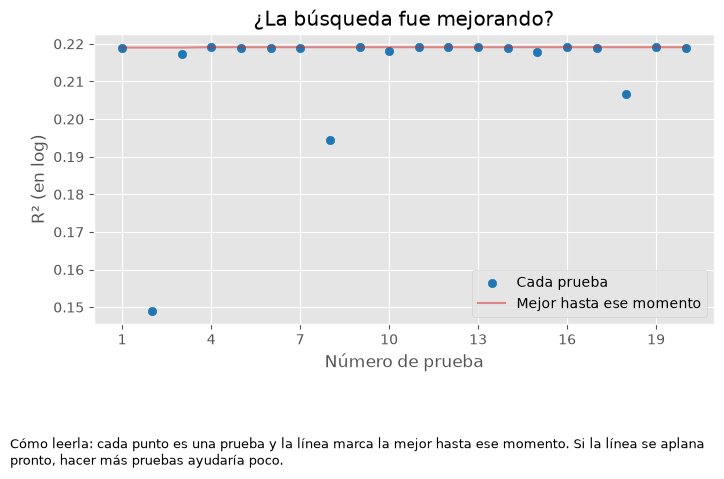

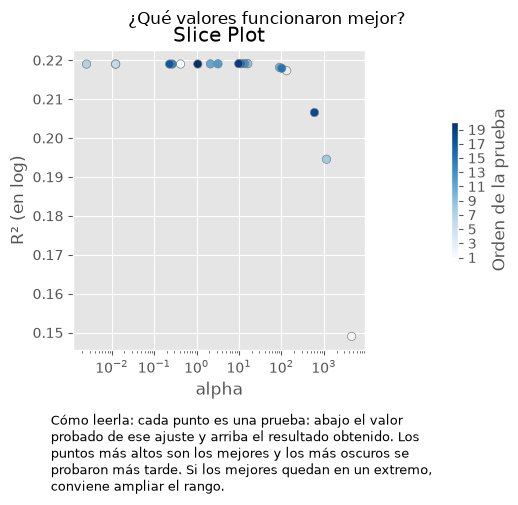

In [ ]:
# --- 2. Regresión (Regresión Lineal Ridge) ---
# Objetivo: y_log_days (solo adoptados), R² en log.

def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(numeric=NUMERIC + NUMERIC_LOG, columns=FEATURES_EXP2_REG)),
                     ("model", Ridge(**params))])

def space_reg(trial):
    return {"alpha": trial.suggest_float("alpha", 1e-3, 1e4, log=True)}

study_reg = tune(
    "linear_reg", make_pipe_reg, space_reg, data.loc[adopted, FEATURES_EXP2_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP2_REG, model_label="Ridge Regression", task_label="regresión",
    params_help={"alpha": "Fuerza de la regularización."},
    n_trials=N_TRIALS)